# 23CSE301 Machine Learning — Capstone Project
## Track 3: Clustering — **Agglomerative Hierarchical Clustering** (Review 2)
### Dataset: *FinRisk* — Credit Risk Dataset (Borrower Segmentation)

**Problem statement.** Group loan applicants into natural borrower segments using demographics, income, loan characteristics, and credit history. This notebook uses the same `credit_risk_dataset.csv` and preprocessing conventions as `clustering_kmeans.ipynb` so the two algorithms can be compared fairly.

**Important:** `loan_status` is not included in the clustering features. It is used only after clustering for post-hoc interpretation. Hierarchical clustering has quadratic memory/time costs, so the main model uses the fixed **8,000-row shared sample** exported by the K-Means notebook when available.


---
## 1. Setup and reproducibility

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

RANDOM_STATE = 42
SAMPLE_N = 8000
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 50)


def cluster_metrics(X, labels, silhouette_sample_size=3000, seed=RANDOM_STATE):
    """Return the three required internal metrics; silhouette is sampled for speed."""
    X = np.asarray(X)
    labels = np.asarray(labels)
    if len(np.unique(labels)) < 2:
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    n_sil = min(silhouette_sample_size, len(X))
    sil = silhouette_score(X, labels, sample_size=n_sil, random_state=seed) if n_sil < len(X) else silhouette_score(X, labels)
    return {"Silhouette": sil,
            "Davies-Bouldin": davies_bouldin_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X, labels)}

print("Environment ready | pandas", pd.__version__, "| numpy", np.__version__)


Environment ready | pandas 2.2.3 | numpy 2.3.5


---
## 2. Load the credit-risk dataset and inspect it

In [2]:
# Notebook is expected inside notebooks/. These paths support running from the
# notebooks folder, repository root, or with the CSV beside the notebook.
CANDIDATE_PATHS = [
    "../data/credit_risk_dataset.csv",
    "data/credit_risk_dataset.csv",
    "credit_risk_dataset.csv",
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "credit_risk_dataset.csv not found. Put it in the repository's data/ folder "
        "or beside this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
EXPECTED = ["person_age", "person_income", "person_home_ownership", "person_emp_length",
            "loan_intent", "loan_grade", "loan_amnt", "loan_int_rate", "loan_status",
            "loan_percent_income", "cb_person_default_on_file", "cb_person_cred_hist_length"]
missing_cols = [c for c in EXPECTED if c not in df_raw.columns]
assert not missing_cols, f"Unexpected schema - missing columns: {missing_cols}"

print("Loaded from:", DATA_PATH)
print("Raw shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.isnull().sum().rename("missing_values").to_frame())


Loaded from: ../data/credit_risk_dataset.csv
Raw shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


,missing_values
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


---
## 3. Preprocess features consistently with K-Means

The following preparation mirrors the K-Means notebook: remove duplicates and implausible age/employment values, impute missing employment length and interest rate, engineer log and credit-history features, encode categories, and standardise continuous features. `loan_status` is held aside and never enters the feature matrix.

In [3]:
# Prefer the exact shared preprocessing exports from the K-Means notebook.
# If those exports have not been created yet, reproduce the same preprocessing here.
scaled_path = "../data/processed/finrisk_features_scaled.csv"
clean_path = "../data/processed/finrisk_clean_unscaled.csv"
label_path = "../data/processed/finrisk_loan_status_labels.csv"
shared_path = "../data/processed/finrisk_shared_sample_idx.csv"
kmeans_labels_path = "../data/processed/finrisk_kmeans_labels.csv"

if all(os.path.exists(p) for p in [scaled_path, clean_path, label_path, shared_path]):
    X_scaled = pd.read_csv(scaled_path)
    df = pd.read_csv(clean_path)
    y_true = pd.read_csv(label_path).iloc[:, 0]
    shared_idx = pd.read_csv(shared_path)["row_index"].to_numpy(dtype=int)
    kmeans_lab = pd.read_csv(kmeans_labels_path)["kmeans_cluster"].to_numpy() if os.path.exists(kmeans_labels_path) else None
    print("Loaded shared preprocessed features exported by clustering_kmeans.ipynb")
else:
    print("K-Means exports not found; applying matching preprocessing locally.")
    df = df_raw.copy()
    start_rows = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    bad_age = df["person_age"] > 100
    bad_emp = df["person_emp_length"] > (df["person_age"] - 14)
    df = df.loc[~(bad_age | bad_emp)].reset_index(drop=True)
    df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
    grade_median_rate = df.groupby("loan_grade")["loan_int_rate"].transform("median")
    df["loan_int_rate"] = df["loan_int_rate"].fillna(grade_median_rate)
    df["loan_int_rate"] = df["loan_int_rate"].fillna(df["loan_int_rate"].median())
    df = df.dropna(subset=EXPECTED).reset_index(drop=True)

    df["log_income"] = np.log1p(df["person_income"])
    df["log_loan_amnt"] = np.log1p(df["loan_amnt"])
    df["credit_hist_ratio"] = df["cb_person_cred_hist_length"] / df["person_age"]
    grade_map = {g: i for i, g in enumerate("ABCDEFG")}
    df["grade_num"] = df["loan_grade"].map(grade_map)
    df["default_on_file"] = (df["cb_person_default_on_file"] == "Y").astype(int)
    y_true = df["loan_status"].copy()
    continuous_cols = ["person_age", "log_income", "person_emp_length", "log_loan_amnt",
                       "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length",
                       "credit_hist_ratio", "grade_num"]
    dummies = pd.get_dummies(df[["person_home_ownership", "loan_intent"]], dtype=int)
    X_unscaled = pd.concat([df[continuous_cols], df[["default_on_file"]], dummies], axis=1)
    scaler = StandardScaler()
    X_scaled = X_unscaled.copy()
    X_scaled[continuous_cols] = scaler.fit_transform(X_unscaled[continuous_cols])
    shared_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(
        len(X_scaled), size=min(SAMPLE_N, len(X_scaled)), replace=False))
    kmeans_lab = None

assert "loan_status" not in X_scaled.columns, "Target leakage: loan_status must not be a feature."
assert len(X_scaled) == len(y_true) == len(df), "Feature/label row counts do not match."
shared_idx = shared_idx[(shared_idx >= 0) & (shared_idx < len(X_scaled))]
X_sample = X_scaled.iloc[shared_idx].to_numpy(dtype=float)
y_sample = np.asarray(y_true).ravel()[shared_idx]
print("Clean rows:", len(df))
print("Feature matrix:", X_scaled.shape)
print("Shared sample:", X_sample.shape)
print("Target excluded from features:", "loan_status" not in X_scaled.columns)


K-Means exports not found; applying matching preprocessing locally.


Clean rows: 32409
Feature matrix: (32409, 20)
Shared sample: (8000, 20)
Target excluded from features: True


---
## 4. Explore the scaled feature matrix

,count,mean,std,min,25%,50%,75%,max
person_age,32409.0,-0.000,1.000,-1.245,-0.762,-0.279,0.365,10.671
log_income,32409.0,-0.000,1.000,-4.656,-0.649,-0.018,0.627,6.376
person_emp_length,32409.0,0.000,1.000,-1.195,-0.693,-0.191,0.562,9.097
log_loan_amnt,32409.0,0.000,1.000,-3.833,-0.597,0.064,0.663,2.139
loan_int_rate,32409.0,0.000,1.000,-1.743,-0.977,-0.009,0.766,3.797
loan_percent_income,32409.0,0.000,1.000,-1.594,-0.752,-0.190,0.560,6.178
cb_person_cred_hist_length,32409.0,-0.000,1.000,-0.939,-0.693,-0.446,0.539,5.961
credit_hist_ratio,32409.0,0.000,1.000,-1.261,-0.747,-0.224,0.716,4.203
grade_num,32409.0,-0.000,1.000,-1.046,-1.046,-0.189,0.668,4.094
default_on_file,32409.0,0.177,0.381,0.000,0.000,0.000,0.000,1.000


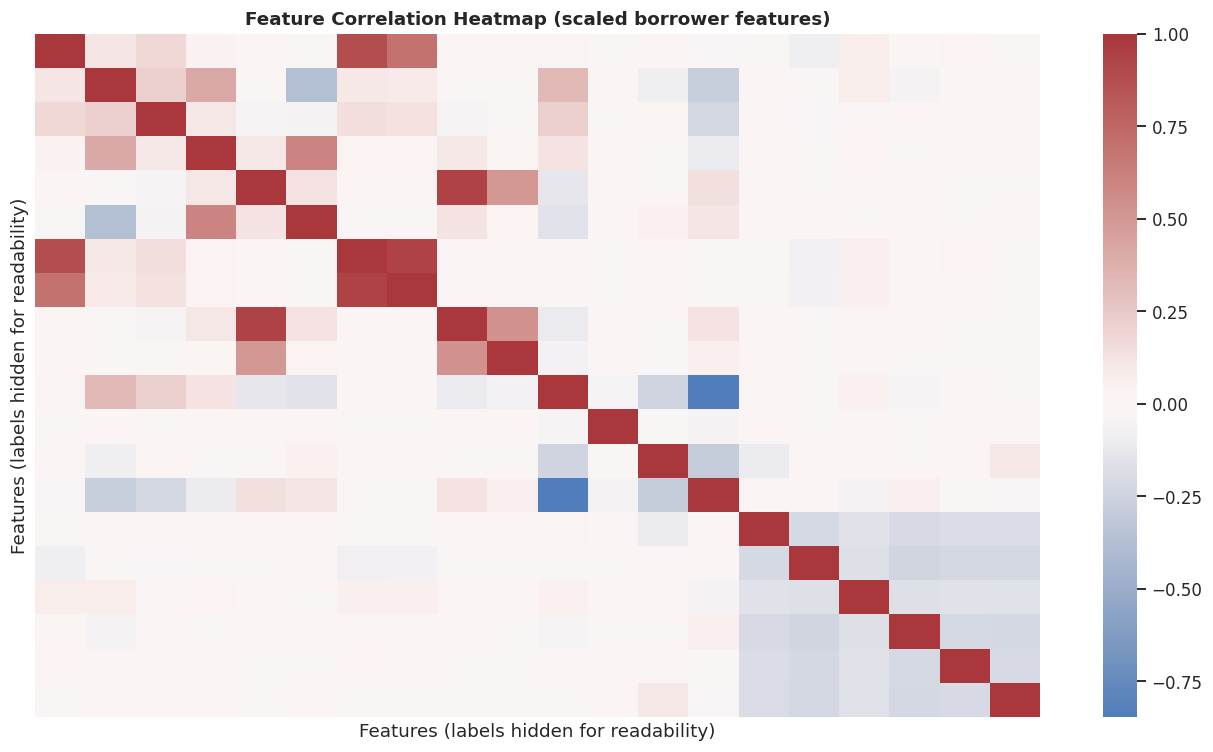

In [4]:
display(X_scaled.describe().T.round(3))
plt.figure(figsize=(12, 7))
sns.heatmap(X_scaled.corr(), cmap="vlag", center=0, xticklabels=False, yticklabels=False)
plt.title("Feature Correlation Heatmap (scaled borrower features)")
plt.xlabel("Features (labels hidden for readability)")
plt.ylabel("Features (labels hidden for readability)")
plt.tight_layout()
plt.show()


---
## 5. Dendrogram on a manageable subset

A full dendrogram with thousands of leaves is unreadable. This plot uses a deterministic subset of at most 1,000 rows to illustrate the merge structure; the final model and metrics below use the shared 8,000-row sample.

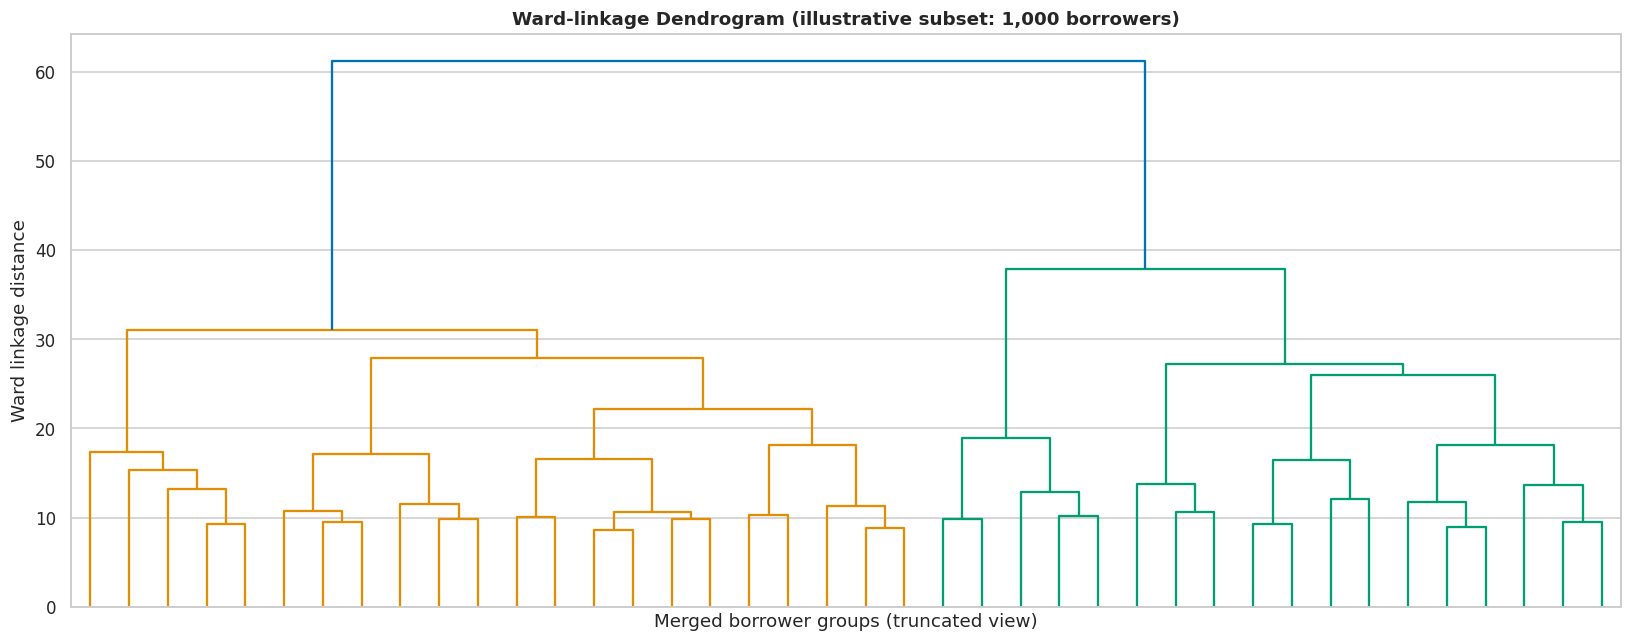

In [5]:
n_dendro = min(1000, len(X_sample))
dendro_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=n_dendro, replace=False))
X_dendro = X_sample[dendro_idx]
Z_ward = linkage(X_dendro, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z_ward, no_labels=True, truncate_mode="lastp", p=40)
plt.title(f"Ward-linkage Dendrogram (illustrative subset: {n_dendro:,} borrowers)")
plt.xlabel("Merged borrower groups (truncated view)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()


---
## 6. Compare linkage strategies

We compare Ward, complete, average, and single linkage on a fixed subset for practical runtime. The subset is drawn from the shared sample, and the random seed is fixed for reproducibility. The selected linkage is then fitted on the full shared sample for the K-Means comparison.

In [6]:
LINKAGE_SAMPLE_N = min(2500, len(X_sample))
linkage_idx = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=LINKAGE_SAMPLE_N, replace=False))
X_linkage = X_sample[linkage_idx]
# Match the k selected in the K-Means notebook when its result export is available.
K_FINAL = 5
km_results_path = "../results/clustering_kmeans_results.csv"
if os.path.exists(km_results_path):
    import re
    km_result_names = pd.read_csv(km_results_path, index_col=0).index.astype(str).tolist()
    shared_name = next((name for name in km_result_names if "shared" in name.lower() and "k=" in name.lower()), None)
    if shared_name:
        match = re.search(r"k=(\d+)", shared_name, flags=re.IGNORECASE)
        if match:
            K_FINAL = int(match.group(1))
print("Number of clusters for comparison (k):", K_FINAL)
linkage_methods = ["ward", "complete", "average", "single"]
comparison_rows = []
labels_by_linkage = {}

for method in linkage_methods:
    t0 = time.time()
    model = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method)
    labels_method = model.fit_predict(X_linkage)
    labels_by_linkage[method] = labels_method
    metrics = cluster_metrics(X_linkage, labels_method, silhouette_sample_size=2000)
    comparison_rows.append({"Linkage": method, **metrics, "Fit time (sec)": round(time.time() - t0, 2)})

linkage_results = pd.DataFrame(comparison_rows).sort_values("Silhouette", ascending=False).reset_index(drop=True)
display(linkage_results.round(4))
best_linkage = str(linkage_results.iloc[0]["Linkage"])
print("Best linkage by silhouette on the linkage-comparison subset:", best_linkage)


Number of clusters for comparison (k): 5


,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Fit time (sec)
0,single,0.5119,0.5517,12.1436,0.19
1,average,0.2861,1.1218,46.7411,0.22
2,complete,0.1407,1.8664,169.3974,0.23
3,ward,0.1020,2.1655,288.1018,0.47


Best linkage by silhouette on the linkage-comparison subset: single


---
## 7. Visualise linkage comparison

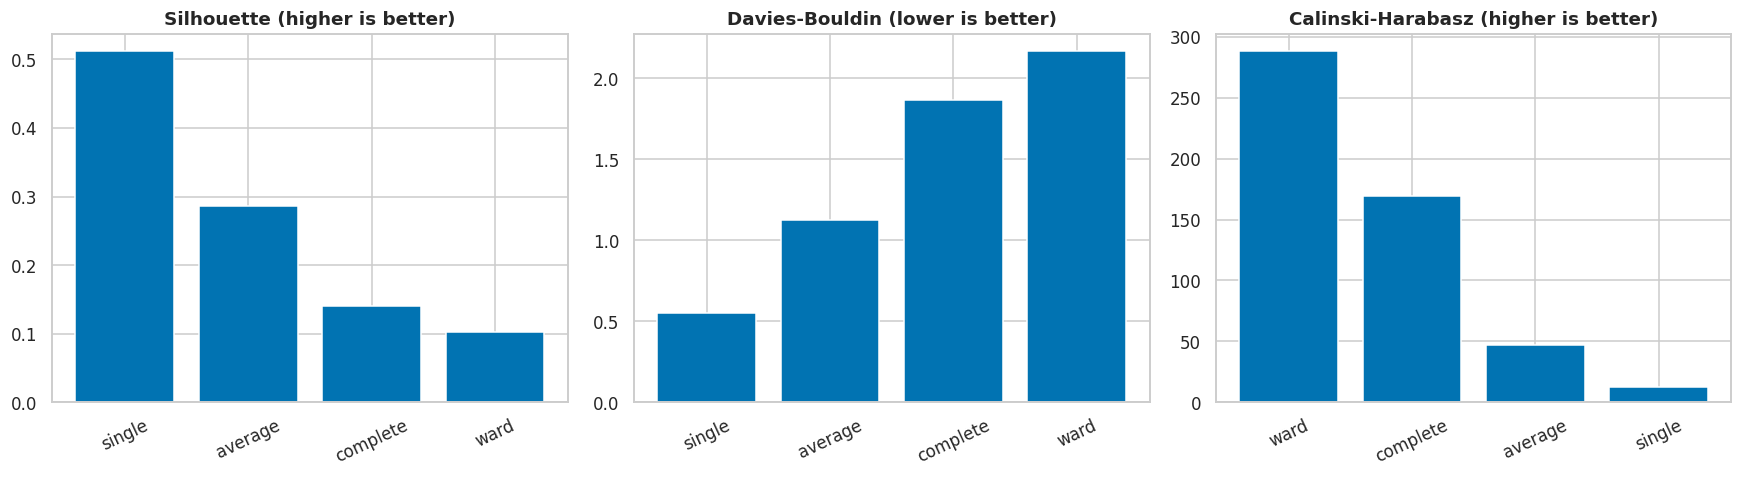

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metric_cols = [("Silhouette", "Silhouette (higher is better)"),
               ("Davies-Bouldin", "Davies-Bouldin (lower is better)"),
               ("Calinski-Harabasz", "Calinski-Harabasz (higher is better)")]
for ax, (col, title) in zip(axes, metric_cols):
    order = linkage_results.sort_values(col, ascending=(col == "Davies-Bouldin"))
    ax.bar(order["Linkage"], order[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


---
## 8. Final Agglomerative model on the shared sample

The main result uses the same shared rows exported by K-Means. Agglomerative clustering does not have a `predict` step for new points; it builds a hierarchy from the observations passed to `fit_predict`. For memory reasons, the model is fitted on the 8,000-row sample, not the entire 32k-row dataset.

In [8]:
final_model = AgglomerativeClustering(n_clusters=K_FINAL, linkage=best_linkage)
t0 = time.time()
agg_labels = final_model.fit_predict(X_sample)
fit_seconds = time.time() - t0

sizes = pd.Series(agg_labels).value_counts().sort_index()
size_table = pd.DataFrame({"cluster": sizes.index, "n_borrowers": sizes.values,
                           "share_%": (sizes.values / len(agg_labels) * 100).round(2)})
print(f"Fit time on {len(X_sample):,} shared rows: {fit_seconds:.1f} sec")
display(size_table)
agg_metrics = cluster_metrics(X_sample, agg_labels, silhouette_sample_size=3000)
agg_metrics_df = pd.DataFrame([agg_metrics], index=[f"Agglomerative ({best_linkage}, k={K_FINAL}) — shared {len(X_sample):,}-row sample"])
display(agg_metrics_df.round(4))


Fit time on 8,000 shared rows: 0.5 sec


,cluster,n_borrowers,share_%
0,0,7996,99.95
1,1,1,0.01
2,2,1,0.01
3,3,1,0.01
4,4,1,0.01


,Silhouette,Davies-Bouldin,Calinski-Harabasz
"Agglomerative (single, k=5) — shared 8,000-row sample",0.545,0.3731,8.2069


---
## 9. PCA visualisation of clusters *(mandatory)*

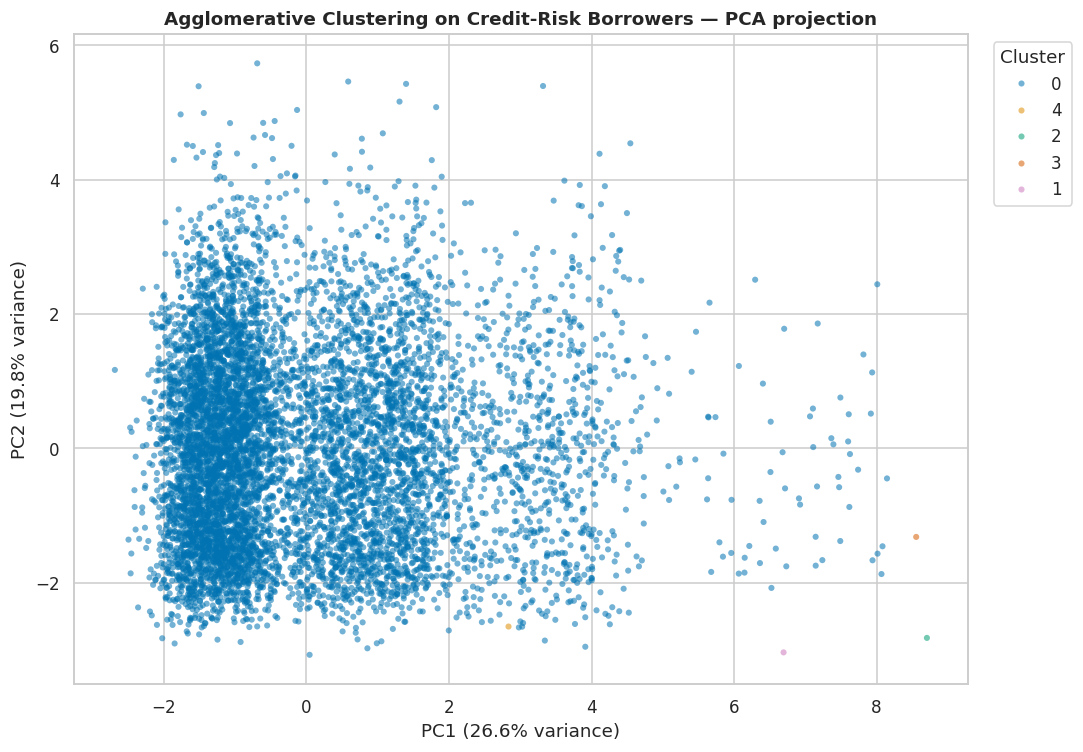

Variance explained by first 2 PCs: 46.42%


In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sample)
plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Cluster": agg_labels.astype(str)})
plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", s=16, alpha=0.55, linewidth=0)
plt.title("Agglomerative Clustering on Credit-Risk Borrowers — PCA projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print(f"Variance explained by first 2 PCs: {pca.explained_variance_ratio_.sum()*100:.2f}%")


---
## 10. Cluster profiling

In [10]:
profile_df = df.iloc[shared_idx].reset_index(drop=True).copy()
profile_df["cluster"] = agg_labels
readable_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
                 "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
profile = profile_df.groupby("cluster")[readable_cols].mean().round(2)
print("Mean original-scale borrower characteristics by cluster:")
display(profile)

for col in ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]:
    print(f"\n{col} mix within each cluster (%):")
    display((pd.crosstab(profile_df["cluster"], profile_df[col], normalize="index") * 100).round(1))


Mean original-scale borrower characteristics by cluster:


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
cluster,,,,,,,
0,27.72,66458.31,4.8,9637.04,10.98,0.17,5.82
1,60.00,1900000.00,5.0,1500.00,7.49,0.00,21.00
2,53.00,95000.00,24.0,6000.00,5.42,0.06,30.00
3,76.00,75000.00,23.0,15000.00,8.94,0.20,25.00
4,43.00,780000.00,2.0,1000.00,8.94,0.00,11.00



person_home_ownership mix within each cluster (%):


person_home_ownership,MORTGAGE,OTHER,OWN,RENT
cluster,,,,
0,41.3,0.3,7.9,50.6
1,100.0,0.0,0.0,0.0
2,0.0,0.0,100.0,0.0
3,0.0,0.0,0.0,100.0
4,100.0,0.0,0.0,0.0



loan_intent mix within each cluster (%):


loan_intent,DEBTCONSOLIDATION,EDUCATION,HOMEIMPROVEMENT,MEDICAL,PERSONAL,VENTURE
cluster,,,,,,
0,16.2,20.0,10.9,19.0,17.0,16.9
1,0.0,0.0,0.0,0.0,100.0,0.0
2,0.0,0.0,0.0,0.0,100.0,0.0
3,0.0,0.0,0.0,100.0,0.0,0.0
4,0.0,0.0,100.0,0.0,0.0,0.0



loan_grade mix within each cluster (%):


loan_grade,A,B,C,D,E,F,G
cluster,,,,,,,
0,33.5,31.7,19.7,11.2,3.0,0.7,0.2
1,100.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100.0,0.0,0.0,0.0,0.0,0.0,0.0
4,100.0,0.0,0.0,0.0,0.0,0.0,0.0



cb_person_default_on_file mix within each cluster (%):


cb_person_default_on_file,N,Y
cluster,,
0,82.5,17.5
1,100.0,0.0
2,100.0,0.0
3,100.0,0.0
4,100.0,0.0


---
## 11. Post-hoc validation against `loan_status`

`loan_status` is used only now, after fitting. These rates help assess whether the unsupervised borrower segments differ in observed default prevalence; they do not turn the clustering task into supervised learning.

Overall default rate in shared sample: 21.64%


,default_rate,n_defaults,n_borrowers,default_rate_%
cluster,,,,
0,0.2165,1731,7996,21.6483
1,0.0000,0,1,0.0000
2,0.0000,0,1,0.0000
3,0.0000,0,1,0.0000
4,0.0000,0,1,0.0000


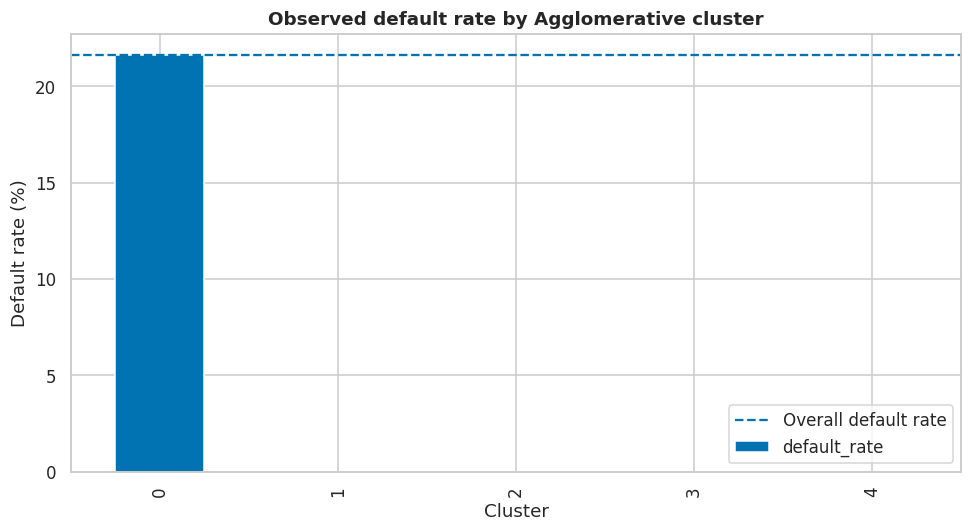

In [11]:
overall_default_rate = float(np.mean(y_sample))
cluster_default = pd.DataFrame({"cluster": agg_labels, "loan_status": y_sample}).groupby("cluster")["loan_status"].agg(["mean", "sum", "count"])
cluster_default.columns = ["default_rate", "n_defaults", "n_borrowers"]
cluster_default["default_rate_%"] = cluster_default["default_rate"] * 100
print(f"Overall default rate in shared sample: {overall_default_rate*100:.2f}%")
display(cluster_default.round(4))

ax = (cluster_default["default_rate"] * 100).plot(kind="bar", figsize=(9, 5))
ax.axhline(overall_default_rate * 100, linestyle="--", label="Overall default rate")
ax.set_title("Observed default rate by Agglomerative cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Default rate (%)")
ax.legend()
plt.tight_layout()
plt.show()


---
## 12. Compare with K-Means on exactly the same rows

In [12]:
comparison = {f"Agglomerative ({best_linkage}, k={K_FINAL})": agg_metrics}
if os.path.exists("../results/clustering_kmeans_results.csv"):
    km_results = pd.read_csv("../results/clustering_kmeans_results.csv", index_col=0)
    km_shared_row = [idx for idx in km_results.index if "shared" in idx.lower()]
    if km_shared_row:
        row = km_results.loc[km_shared_row[0]]
        comparison["K-Means (shared sample)"] = {
            "Silhouette": row.get("Silhouette", row.get("Silhouette score", np.nan)),
            "Davies-Bouldin": row.get("Davies-Bouldin", row.get("Davies-Bouldin index", np.nan)),
            "Calinski-Harabasz": row.get("Calinski-Harabasz", row.get("Calinski-Harabasz index", np.nan)),
        }
    else:
        print("K-Means results file found, but no shared-sample row was recognised.")
else:
    print("K-Means results export not found. Run clustering_kmeans.ipynb first for the comparison table.")

comparison_df = pd.DataFrame(comparison).T
comparison_df.index.name = "Algorithm"
display(comparison_df.round(4))

if kmeans_lab is not None and len(kmeans_lab) == len(X_scaled):
    km_shared_labels = kmeans_lab[shared_idx]
    print("ARI between K-Means and Agglomerative labels on the shared sample:",
          round(adjusted_rand_score(km_shared_labels, agg_labels), 4))
    print("NMI between K-Means and Agglomerative labels on the shared sample:",
          round(normalized_mutual_info_score(km_shared_labels, agg_labels), 4))


K-Means results export not found. Run clustering_kmeans.ipynb first for the comparison table.


,Silhouette,Davies-Bouldin,Calinski-Harabasz
Algorithm,,,
"Agglomerative (single, k=5)",0.545,0.3731,8.2069


---
## 13. Export results

In [13]:
os.makedirs("../results", exist_ok=True)
agg_metrics_df.to_csv("../results/clustering_agglomerative_results.csv")
linkage_results.to_csv("../results/clustering_agglomerative_linkage_comparison.csv", index=False)
size_table.to_csv("../results/clustering_agglomerative_cluster_sizes.csv", index=False)
cluster_default.to_csv("../results/clustering_agglomerative_default_rates.csv")
# Save labels aligned to the exact shared sample order used for fitting.
pd.DataFrame({"row_index": shared_idx, "agglomerative_cluster": agg_labels}).to_csv(
    "../results/clustering_agglomerative_shared_labels.csv", index=False)
print("Saved Agglomerative outputs in ../results/")


Saved Agglomerative outputs in ../results/
